In [4]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = r"D:\WEIXINYI\test\Sig_Eqs.tsv"

Sig_Eqs = pd.read_csv(
    DATA_FILE,
    sep="\t",
    skiprows=[1],
    low_memory=False
)

print(Sig_Eqs.shape)
Sig_Eqs.head()

(6697, 49)


,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
0,NaN,1,-2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,2,-2000,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,3,-2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
3,NaN,5877,-1610,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
4,NaN,8,-1566,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#1.1 各国累计死亡人数

In [5]:
deaths_by_country = (
    Sig_Eqs.groupby("Country", as_index=False)["Total Deaths"]
    .sum()
)

deaths_by_country = deaths_by_country.sort_values(
    "Total Deaths",
    ascending=False
)

top20_deaths = deaths_by_country.head(20).copy()

top20_deaths["Total Deaths"] = (
    top20_deaths["Total Deaths"]
    .astype(int)
)

top20_deaths = top20_deaths.reset_index(drop=True)
top20_deaths.index = range(1, len(top20_deaths) + 1)

print(top20_deaths)

         Country  Total Deaths
1          CHINA       2106526
2         TURKEY       1008867
3           IRAN        761656
4          SYRIA        488326
5          ITALY        417297
6          HAITI        323782
7          JAPAN        319510
8     AZERBAIJAN        319251
9      INDONESIA        283485
10       ARMENIA        175000
11      PAKISTAN        143714
12       ECUADOR        134445
13  TURKMENISTAN        110412
14          PERU         97009
15        GREECE         83658
16      PORTUGAL         82572
17          IRAQ         70200
18         CHILE         70175
19         INDIA         63413
20        ISRAEL         58368


In [ ]:
#1.2 每年Ms>3.0的地震数量

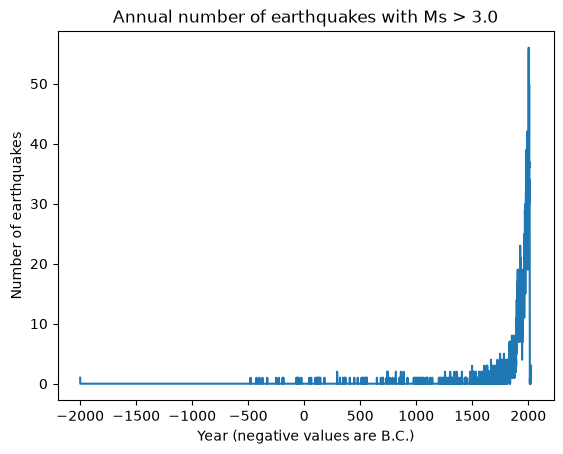

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

ms = pd.to_numeric(
    Sig_Eqs["Ms"],
    errors="coerce"
)

ms_events = Sig_Eqs.loc[ms > 3.0]

annual_counts = ms_events.groupby("Year").size()

year_range = range(
    int(ms_events["Year"].min()),
    int(ms_events["Year"].max()) + 1
)

annual_counts = annual_counts.reindex(
    year_range,
    fill_value=0
)

annual_counts.plot()
plt.title("Annual number of earthquakes with Ms > 3.0")
plt.xlabel("Year (negative values are B.C.)")
plt.ylabel("Number of earthquakes")
plt.show()

In [8]:
def CountEq_LargestEq(country):
    country_events = Sig_Eqs.loc[
        Sig_Eqs["Country"] == country
    ]

    total_count = len(country_events)

    if total_count == 0:
        return 0, None, None

    events_with_mag = country_events.dropna(
        subset=["Mag"]
    )

    if events_with_mag.empty:
        return total_count, None, None

    largest = events_with_mag.sort_values(
        "Mag",
        ascending=False
    ).iloc[0]

    year = int(largest["Year"])

    if year < 0:
        event_date = f"{abs(year)} B.C."
    else:
        event_date = str(year)

    if not pd.isna(largest["Mo"]):
        month = int(largest["Mo"])
        event_date = f"{event_date}-{month:02d}"

        if not pd.isna(largest["Dy"]):
            day = int(largest["Dy"])
            event_date = f"{event_date}-{day:02d}"

    location = largest["Location Name"]

    return total_count, event_date, location


results = []

for country in Sig_Eqs["Country"].dropna().unique():
    count, date, location = CountEq_LargestEq(country)

    results.append({
        "Country": country,
        "Total Earthquakes": count,
        "Largest Earthquake Date": date,
        "Largest Earthquake Location": location
    })

country_summary = pd.DataFrame(results)

country_summary = country_summary.sort_values(
    "Total Earthquakes",
    ascending=False
).reset_index(drop=True)

country_summary.index = range(
    1,
    len(country_summary) + 1
)

print(country_summary)

            Country  Total Earthquakes Largest Earthquake Date  \
1             CHINA                626              1668-07-25   
2             JAPAN                429              2011-03-11   
3         INDONESIA                427              2004-12-26   
4              IRAN                385               856-12-22   
5            TURKEY                359              1939-12-26   
..              ...                ...                     ...   
158         BURUNDI                  1              2004-02-24   
159  CZECH REPUBLIC                  1              2008-11-22   
160      MADAGASCAR                  1              2017-01-11   
161          ZAMBIA                  1              2017-02-24   
162         COMOROS                  1              2018-05-15   

                     Largest Earthquake Location  
1                      CHINA:  SHANDONG PROVINCE  
2                                 JAPAN:  HONSHU  
3    INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST  
4  